# Quantitative analysis of two portfolios (USD)
*Análisis cuantitativo de dos portafolios de un inversor argentino.*

This notebook walks through the pipeline step by step. The full interactive report is `reports/portfolio_report.html` (run `python main.py`).

1. Data & proxies · 2. Bond total return · 3. Metrics · 4. Backtest · 5. Robustness · 6. Stress scenarios · 7. Outlook from today's prices

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import pandas as pd
from IPython.display import Image, display
pd.set_option('display.float_format', '{:,.4f}'.format)
import main
from src import config, cashflows

## 1. Data and proxies
US-listed assets come from yfinance. Argentine bonds from data912, the CCL rate and the FCI from ArgentinaDatos, CER/TAMAR from the BCRA API. Assets without public history use a documented proxy (see `data/README.md`).

In [2]:
built = main.stage_data(refresh=False)
built['coverage'][['asset','source_type','first_real_date','real_data_share','note']]

== Stage 1: data ==


Window: 2021-10-25 -> 2026-10-23 (1255 trading days)
      asset source_type          series first_real_date  real_data_share
       AL35        real        AL35D_TR      2021-09-23           1.0000
       AO27       proxy        AL30D_TR            None           0.0000
      YMCXO       proxy        ON_BLEND            None           0.0000
      VSCRO       proxy        ON_BLEND            None           0.0000
      TTCDO       proxy        ON_BLEND            None           0.0000
FCI_IOL_DAP  real+proxy FCI_DAP_SPLICED      2024-11-01           0.3940
      TXMD9   synthetic  DUAL_SYNTH_USD            None           0.0000
        SPY        real             SPY      2021-08-26           1.0000
       IEUR        real            IEUR      2021-08-26           1.0000
        QQQ        real             QQQ      2021-08-26           1.0000
      GOOGL        real           GOOGL      2021-08-26           1.0000
       NVDA        real            NVDA      2021-08-26           1.000

,asset,source_type,first_real_date,real_data_share,note
0,AL35,real,2021-09-23,1.0000,data912 AL35D (USD MEP) + coupons reinvested (total return).
1,AO27,proxy,None,0.0000,No public price history for AO27 (issued 2025). Proxy: AL30D total...
2,YMCXO,proxy,None,0.0000,No public history for this ON. Base proxy: 50% CEMB + 50% AL30D to...
3,VSCRO,proxy,None,0.0000,No public history for this ON. Base proxy: 50% CEMB + 50% AL30D to...
4,TTCDO,proxy,None,0.0000,No public history for this ON. Base proxy: 50% CEMB + 50% AL30D to...
5,FCI_IOL_DAP,real+proxy,2024-11-01,0.3940,"Real NAV (ArgentinaDatos/CAFCI, Clase D) when available; BIL (US T..."
6,TXMD9,synthetic,None,0.0000,"No history (issued 2025). Synthetic: monthly max(CER, TAMAR) accru..."
7,SPY,real,2021-08-26,1.0000,"yfinance, dividend-adjusted close (US-listed underlying)."
8,IEUR,real,2021-08-26,1.0000,"yfinance, dividend-adjusted close (US-listed underlying)."
9,QQQ,real,2021-08-26,1.0000,"yfinance, dividend-adjusted close (US-listed underlying)."


## 2. Bond total return
Argentine bond prices drop on the ex-date by the coupon + amortization. The table checks that the price drop matches the scheduled cash flow.

In [3]:
built['bond_checks']['AL30D']

,payment_date,ex_date,cash_flow,price_before,price_ex,price_drop
0,2022-01-09,2022-01-07,0.2500,31.0300,30.2200,0.8100
1,2022-07-09,2022-07-08,0.2500,18.9800,18.5100,0.4700
2,2023-01-09,2023-01-06,0.2500,25.6000,25.5800,0.0200
3,2023-07-09,2023-07-07,0.2500,28.2900,28.1500,0.1400
4,2024-01-09,2024-01-08,0.3750,37.6900,36.4000,1.2900
5,2024-07-09,2024-07-08,4.3750,53.1500,49.4200,3.7300
6,2025-01-09,2025-01-08,8.3600,76.9500,68.6000,8.3500
7,2025-07-09,2025-07-08,8.3300,68.0800,59.9500,8.1300
8,2026-01-09,2026-01-08,8.3000,67.1100,58.5300,8.5800
9,2026-07-09,2026-07-08,8.2700,64.4000,55.9600,8.4400


In [4]:
e = built['extras']
def cagr(s): s = s.dropna(); return (s.iloc[-1]/s.iloc[0])**(365.25/(s.index[-1]-s.index[0]).days)-1
pd.DataFrame({'price only': [cagr(e['AL30D_PRICE']), cagr(e['AL35D_PRICE'])],
              'total return': [cagr(e['AL30D_TR']), cagr(e['AL35D_TR'])]}, index=['AL30D','AL35D'])

,price only,total return
AL30D,0.0897,0.2414
AL35D,0.1610,0.2356


## 3. Portfolio metrics and 4. Backtest

In [5]:
analysis = main.stage_analysis(built)


== Stage 2: metrics and backtest ==


                 CAGR Volatility Sharpe Sortino Max drawdown Calmar     DD peak   DD trough DD recovery Best month Worst month % positive months
A (income)      14.7%      16.7%   0.68    1.06       -36.7%   0.40  2021-11-08  2022-10-14  2024-01-23      19.3%      -11.2%             63.3%
B (growth)      38.9%      26.2%   1.24    1.89       -31.7%   1.23  2022-03-29  2022-07-14  2023-02-02      30.3%      -15.3%             68.3%
Combined 60/40  24.3%      18.3%   1.07    1.66       -32.7%   0.74  2021-11-09  2022-10-14  2023-06-26      21.3%      -12.0%             65.0%
SPY             12.3%      17.2%   0.54    0.78       -24.5%   0.50  2022-01-03  2022-10-12  2023-12-13      10.5%       -9.2%             61.7%

Weekly correlation A/B/SPY:
            A (income)  B (growth)    SPY
A (income)      1.0000      0.6700 0.4400
B (growth)      0.6700      1.0000 0.7000
SPY             0.4400      0.7000 1.0000



Backtest:
                           Invested (USD) Final value (USD) Profit (USD) Multiple Money-weighted return (XIRR) Time-weighted CAGR Max drawdown (TWR) Fees paid (USD)
Your strategy (no selling)         12,200            26,353       14,153     2.16                        31.1%              24.5%             -31.0%              72
Full rebalance                     12,200            26,432       14,232     2.17                        31.2%              24.3%             -30.9%             229
100% SPY                           12,200            18,785        6,585     1.54                        17.2%              11.6%             -25.3%              79
100% A                             12,200            21,343        9,143     1.75                        22.4%              15.6%             -33.3%              67
100% B                             12,200            33,867       21,667     2.78                        41.8%              35.6%             -31.7%              79

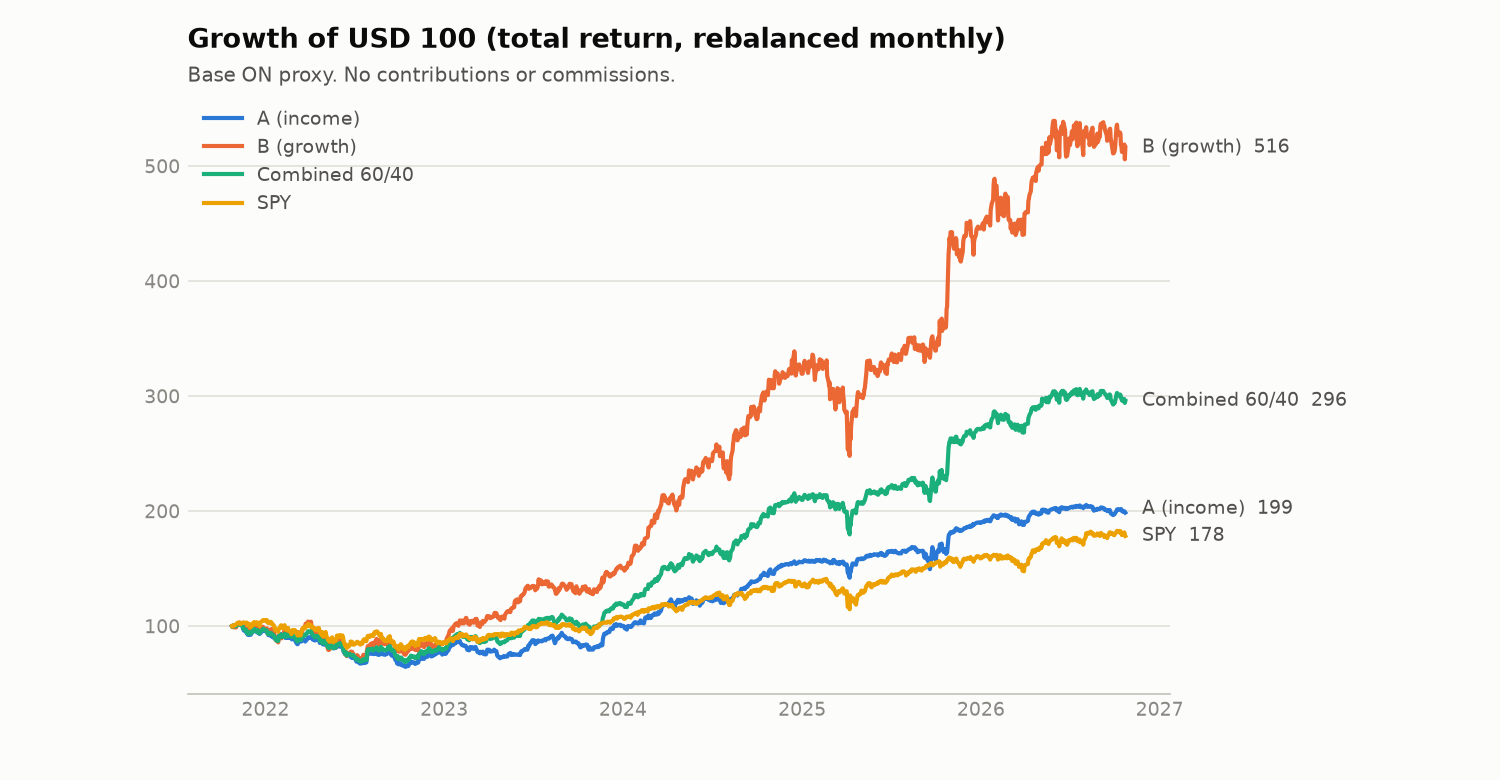

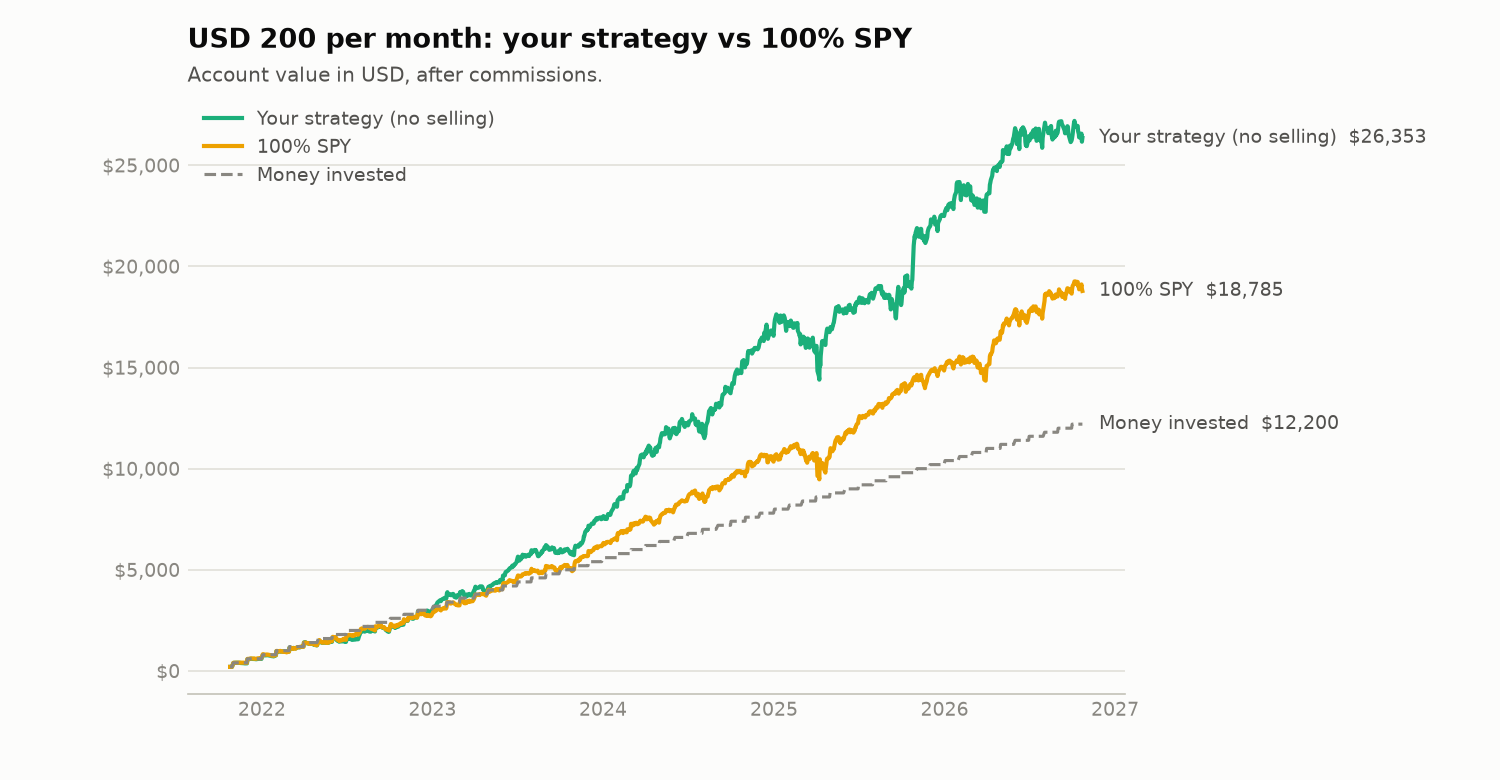

In [6]:
display(Image(str(config.REPORTS / 'figures' / 'growth.png')))
display(Image(str(config.REPORTS / 'figures' / 'backtest.png')))

## 5. Robustness (from Oct-2024) and 7. Outlook

In [7]:
extra = main.stage_robustness(built, analysis, refresh=False)


== Robustness: window from 2024-10-01 ==


                 CAGR Volatility Sharpe Max drawdown
A (income)      18.9%      14.2%   1.01       -11.4%
B (growth)      34.6%      26.2%   1.12       -26.8%
Combined 60/40  25.2%      17.5%   1.15       -16.6%
SPY             16.4%      16.4%   0.77       -18.8%
                           Invested (USD) Final value (USD) Profit (USD) Multiple Money-weighted return (XIRR) Time-weighted CAGR Max drawdown (TWR) Fees paid (USD)
Your strategy (no selling)          5,000             5,958          958     1.19                        17.5%              21.3%             -18.0%              30
Full rebalance                      5,000             6,010        1,010     1.20                        18.4%              22.1%             -18.1%              39
100% SPY                            5,000             5,904          904     1.18                        16.5%              15.1%             -19.0%              33
100% A                              5,000             5,635          635   

## 6. Stress scenarios

In [8]:
stress = main.stage_scenarios(analysis)


== Stress scenarios ==
portfolio                                                                  A (income) B (growth) Combined 60/40     SPY
peak       event                                                                                                       
2022-01-03 2022: Fed hikes, tech sell-off and Argentine bond crisis            -31.8%     -22.5%         -28.0%  -24.5%
2023-08-29 Aug-Oct 2023: US rates spike, Argentine pre-election volatility     -15.5%      -6.3%         -11.9%   -6.6%
2025-02-19 Feb-Apr 2025: US tariff shock                                        -9.3%     -24.4%         -15.6%  -18.8%
2025-08-13 Aug-Oct 2025: Argentine pre-election stress                         -11.4%      -4.9%          -8.8%    3.2%
2026-01-27 Jan-Mar 2026: US equity correction                                   -4.3%      -9.0%          -6.1%   -8.9%


## Key takeaways
- Over 5 years the strategy beat SPY, but with more drawdown in Argentine stress episodes.
- From Oct-2024 the advantage almost disappears.
- The historical numbers carry hindsight bias (asset selection, country-risk compression from ~1,700 bps). From today's prices the expected return of the 60/40 is close to SPY's.

See the HTML report for the full discussion.